# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

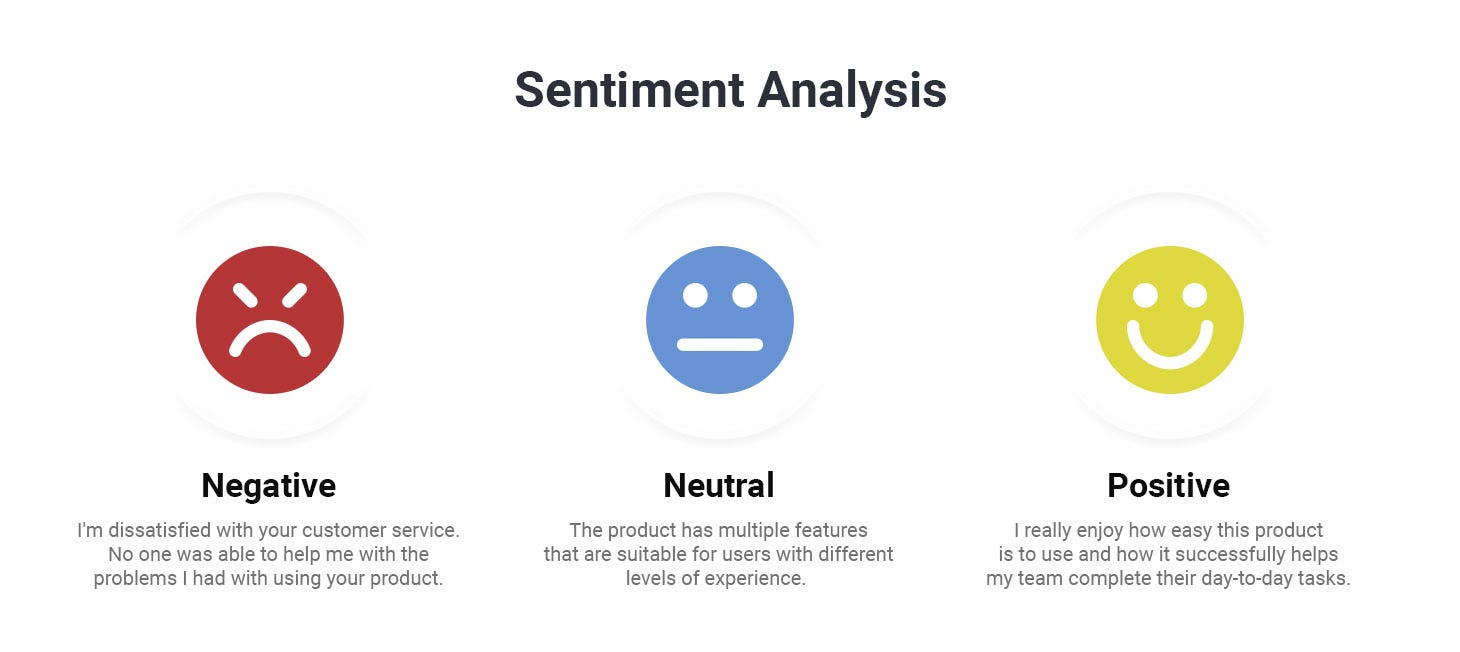

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
import os
import pandas as pd

file_path = '/content/DisneylandReviews.csv'
if not os.path.exists(file_path):   # not on Colab -> download it with kagglehub
    import kagglehub
    file_path = os.path.join(kagglehub.dataset_download("arushchillar/disneyland-reviews"), "DisneylandReviews.csv")

data = pd.read_csv(file_path, encoding='latin-1')
data

C:\Users\Majed AL-Hajri\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

In [9]:
# ===================== Task 1: Load the data =====================
import os
import re
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")
phones = pd.read_csv(os.path.join(path, "Amazon_Unlocked_Mobile.csv"))

print("Shape:", phones.shape)
phones.head()

Shape: (413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


### Task 1: Five preprocessing steps
1. **Remove missing values** in `Reviews` / `Rating`
2. **Remove duplicate reviews**
3. **Lower-case** the text
4. **Remove URLs, numbers, punctuation and special characters**
5. **Remove stop words** (keeping negations like *not*, *no* — they matter for sentiment)
6. *(bonus)* **Stemming** with the Porter stemmer

Then map the star rating to a sentiment label (same rule as the Disneyland example): `> 3` positive, `< 3` negative, `= 3` neutral.

In [10]:
import nltk
from functools import lru_cache
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords', quiet=True)

# Step 1: remove missing values
phones = phones.dropna(subset=['Reviews', 'Rating'])

# Step 2: remove duplicate reviews
phones = phones.drop_duplicates(subset=['Reviews'])
print("Rows after removing missing values & duplicates:", len(phones))

stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor', "don't", "didn't", "doesn't", "isn't", "wasn't", "won't"}
stemmer = PorterStemmer()
stem = lru_cache(maxsize=None)(stemmer.stem)   # cache stems -> much faster

def preprocess_review(text):
    text = text.lower()                                   # Step 3: lower-case
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)    # Step 4: remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)                 #         remove numbers, punctuation, special chars
    words = [w for w in text.split() if w not in stop_words]   # Step 5: remove stop words
    words = [stem(w) for w in words]                      # Step 6: stemming
    return " ".join(words)

phones['Clean_Review'] = phones['Reviews'].astype(str).apply(preprocess_review)
phones = phones[phones['Clean_Review'].str.len() > 0]

# Map star ratings to sentiments
phones['Sentiment'] = phones['Rating'].apply(lambda r: 'positive' if r > 3 else ('negative' if r < 3 else 'neutral'))

print(phones['Sentiment'].value_counts())
phones[['Reviews', 'Clean_Review', 'Sentiment']].head()

Rows after removing missing values & duplicates: 162490


Sentiment
positive    103644
negative     44328
neutral      14359
Name: count, dtype: int64


,Reviews,Clean_Review,Sentiment
0,I feel so LUCKY to have found this used (phone...,feel lucki found use phone us not use hard pho...,positive
1,"nice phone, nice up grade from my pantach revu...",nice phone nice grade pantach revu clean set e...,positive
2,Very pleased,pleas,positive
3,It works good but it goes slow sometimes but i...,work good goe slow sometim good phone love,positive
4,Great phone to replace my lost phone. The only...,great phone replac lost phone thing volum butt...,positive


### Task 2: Train / test split
80% training, 20% testing. `stratify` keeps the same proportion of positive / negative / neutral reviews in both sets.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    phones['Clean_Review'], phones['Sentiment'],
    test_size=0.2, random_state=42, stratify=phones['Sentiment'])

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (129864,)
Testing set : (32467,)


### Task 3: Feature extraction using TF-IDF

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))   # unigrams + bigrams (e.g. "not good")
X_train_tfidf = tfidf.fit_transform(X_train)                     # fit only on the training data
X_test_tfidf = tfidf.transform(X_test)

print("Train TF-IDF matrix:", X_train_tfidf.shape)
print("Test TF-IDF matrix :", X_test_tfidf.shape)

Train TF-IDF matrix: (129864, 5000)
Test TF-IDF matrix : (32467, 5000)


### Task 4: Train a Naive Bayes classifier

In [13]:
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[35462.,11487.,82915.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.3 ,-2.43,-0.45]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](3,)","['negative','neutral','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 5000)","[[ 12.15,168.76, 9.6 ,..., 7.3 , 7.92, 1.68], [ 8.38, 54.88, 2.4 ,..., 4.32, 1.46, 1.12], [ 57.34,264.88, 15.53,..., 27.38, 20.7 , 12.77]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 5000)","[[ -9.39, -6.84, -9.61,..., -9.85, -9.78,-10.98], [ -8.69, -6.91, -9.71,..., -9.26,-10.03,-10.18], [ -8.64, -7.13, -9.91,..., -9.36, -9.63,-10.09]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


### Task 5: Evaluate the model on the test set

In [14]:
from sklearn.metrics import accuracy_score, classification_report

nb_predictions = nb_classifier.predict(X_test_tfidf)

print(f"Accuracy: {accuracy_score(y_test, nb_predictions):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_predictions))

Accuracy: 0.8253

Classification Report:


              precision    recall  f1-score   support

    negative       0.79      0.78      0.78      8866
     neutral       0.37      0.04      0.08      2872
    positive       0.85      0.95      0.90     20729

    accuracy                           0.83     32467
   macro avg       0.67      0.59      0.59     32467
weighted avg       0.79      0.83      0.79     32467



### Task 6: Confusion matrix

[[ 6934    81  1851]
 [ 1012   128  1732]
 [  863   133 19733]]


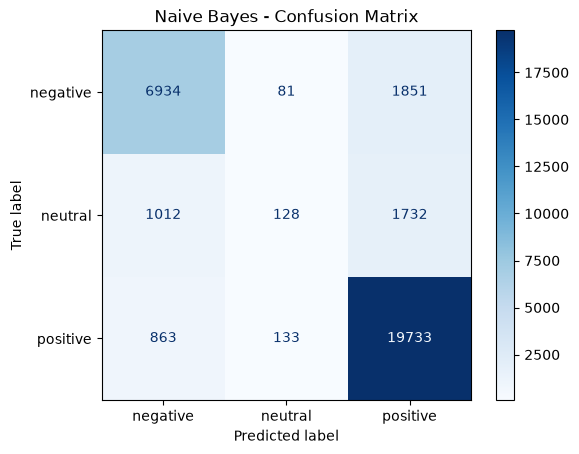

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_test, nb_predictions, labels=labels)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues', values_format='d')
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

### Discussion of the results

- **Overall accuracy: 82.5%** on 32,467 test reviews.
- **Positive** reviews are classified very well (recall 0.95, F1 0.90) and **negative** reviews reasonably well (F1 0.78).
- **Neutral** reviews are almost never predicted (recall 0.04). Most 3-star reviews are classified as negative (1,012) or positive (1,732).

**Why?** The data is **imbalanced**: about 64% positive, 27% negative and only ~9% neutral. Naive Bayes favours the large classes. Neutral reviews also usually mix good and bad points (*"good screen but bad battery"*), so their words overlap with both other classes. Accuracy alone is therefore misleading here, and the **macro-averaged F1 (0.59)** shows the real weakness.

**Possible improvements:** balance the classes (class weights, over/under-sampling), use `ComplementNB` (designed for imbalanced text), or try Logistic Regression / Linear SVM.